In [58]:
import numpy as np


# логарифмическая функция потерь
def loss(w, x, y):
    M = np.dot(w, x) * y
    return np.log2(1 + np.exp(-M))


# производная логарифмической функции потерь по вектору w
def df(w, x, y):
    M = np.dot(w, x) * y
    return -(np.exp(-M) * x.T * y) / ((1 + np.exp(-M)) * np.log(2))


data_x = [(3.0, 4.9), (2.7, 3.9), (3.0, 5.5), (2.6, 4.0), (2.9, 4.3), (3.1, 5.1), (2.2, 4.5), (2.3, 3.3), (2.7, 5.1), (3.3, 5.7), (2.8, 5.1), (2.8, 4.9), (2.5, 4.5), (2.8, 4.7), (3.2, 4.7), (3.2, 5.7), (2.8, 6.1), (3.6, 6.1), (2.8, 4.8), (2.9, 4.5), (3.1, 4.9), (2.3, 4.4), (3.3, 6.0), (2.6, 5.6), (3.0, 4.4), (2.9, 4.7), (2.8, 4.0), (2.5, 5.8), (2.4, 3.3), (2.8, 6.7), (3.0, 5.1), (2.3, 4.0), (3.1, 5.5), (2.8, 4.8), (2.7, 5.1), (2.5, 4.0), (3.1, 4.4), (3.8, 6.7), (3.1, 5.6), (3.1, 4.7), (3.0, 5.8), (3.0, 5.2), (3.0, 4.5), (2.7, 4.9), (3.0, 6.6), (2.9, 4.6), (3.0, 4.6), (2.6, 3.5), (2.7, 5.1), (2.5, 5.0), (2.0, 3.5), (3.2, 5.9), (2.5, 5.0), (3.4, 5.6), (3.4, 4.5), (3.2, 5.3), (2.2, 4.0), (2.2, 5.0), (3.3, 4.7), (2.7, 4.1), (2.4, 3.7), (3.0, 4.2), (3.2, 6.0), (3.0, 4.2), (3.0, 4.5), (2.7, 4.2), (2.5, 3.0), (2.8, 4.6), (2.9, 4.2), (3.1, 5.4), (2.5, 4.9), (3.2, 5.1), (2.8, 4.5), (2.8, 5.6), (3.4, 5.4), (2.7, 3.9), (3.0, 6.1), (3.0, 5.8), (3.0, 4.1), (2.5, 3.9), (2.4, 3.8), (2.6, 4.4), (2.9, 3.6), (3.3, 5.7), (2.9, 5.6), (3.0, 5.2), (3.0, 4.8), (2.7, 5.3), (2.8, 4.1), (2.8, 5.6), (3.2, 4.5), (3.0, 5.9), (2.9, 4.3), (2.6, 6.9), (2.8, 5.1), (2.9, 6.3), (3.2, 4.8), (3.0, 5.5), (3.0, 5.0), (3.8, 6.4)]
data_y = [1, -1, 1, -1, -1, 1, -1, -1, -1, 1, 1, 1, 1, -1, -1, 1, 1, 1, -1, -1, -1, -1, 1, 1, -1, -1, -1, 1, -1, 1, 1, -1, 1, 1, 1, -1, -1, 1, 1, -1, 1, 1, -1, 1, 1, -1, -1, -1, 1, 1, -1, 1, 1, 1, -1, 1, -1, 1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, 1, -1, 1, -1, 1, 1, -1, 1, 1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, -1, 1, -1, 1, -1, 1, 1, 1, -1, 1, -1, 1]

x_train = np.array([[1, x[0], x[1]] for x in data_x])
y_train = np.array(data_y)

n_train = len(x_train)  # размер обучающей выборки
w = np.array([0.0, 0.0, 0.0])  # начальные весовые коэффициенты
nt = np.array([0.5, 0.01, 0.01])   # шаг обучения для каждого параметра w0, w1, w2
lm = 0.01  # значение параметра лямбда для вычисления скользящего экспоненциального среднего
N = 1000  # число итераций алгоритма SGD

M = x_train @ w
Qe = np.mean([loss(w, x_train[i], y_train[i]) for i in range(n_train)])
np.random.seed(0) # генерация одинаковых последовательностей псевдослучайных чисел

# здесь продолжайте программу

for i in range(N):
    k = np.random.randint(0, n_train) # n_train - размер выборки (массива x_train)
    
    grad = df(w, x_train[k], y_train[k])
    w = w - nt * grad
    Qe = lm*loss(w, x_train[k], y_train[k]) + (1-lm)*Qe
    
M = (x_train @ w) * y_train
Q = np.mean(M<0)
    
print(w)
print(Qe)
print(Q)


[-8.42485194 -0.13897743  1.77845675]
0.376965892819133
0.08


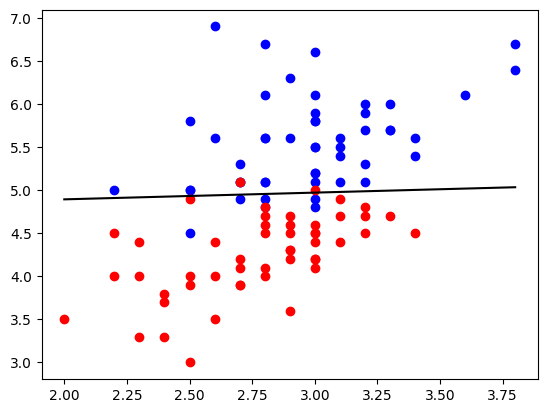

In [59]:
import matplotlib.pyplot as plt

x_line = np.linspace(
    np.min(x_train[:, 1]),
    np.max(x_train[:, 1]),
    100
)

y_line = -(w[0] + w[1] * x_line) / w[2]

plt.scatter(
    x_train[y_train == 1, 1],
    x_train[y_train == 1, 2],
    color='blue'
)

plt.scatter(
    x_train[y_train == -1, 1],
    x_train[y_train == -1, 2],
    color='red'
)

plt.plot(x_line, y_line, color='black')

plt.show()

In [60]:
print(M)

[-0.12734613  1.86410966  0.93972792  1.67236624  1.18052244  0.21444747
  0.72754689  2.87559274 -0.27003845  1.25372604  0.2561407  -0.09955065
 -0.76924012  0.455242    0.51083297  1.26762378  2.03459746  1.92341551
  0.27739632  0.82483109  0.14124388  0.91929031  1.78726307  1.17316457
  1.01657451  0.46913974  1.70016173  1.54275366  2.88949048  3.10167151
  0.22834522  1.63067301  0.92583018 -0.27739632  0.27003845  1.6584685
  1.03047225  2.96269408  1.10367585  0.49693523  1.47326495  0.40619089
  0.83872884 -0.0856529   2.89603035  0.64698542  0.66088316  2.56159462
  0.27003845  0.11998826  2.47820816  1.62331513  0.11998826  1.06198262
  0.89431981  0.55624108  1.61677527  0.16168149  0.52473071  1.50841831
  2.17810778  1.37226586  1.80116081  1.37226586  0.83872884  1.33057263
  3.43692525  0.63308767  1.35836812  0.7479845   0.05785742  0.20054973
  0.81093335  1.14536908  0.70629127  1.86410966  2.00680197  1.47326495
  1.55011154  1.83631417  2.00026211  0.96098354  2.